In [2]:
import os

print(os.listdir("/content"))

['.config', 'train.csv', 'Spaphish dataset - DiB.csv', 'test.csv', 'sample_data']


In [3]:
from pathlib import Path

DATA_DIR = Path("/content")

SPAPHISH_PATH = DATA_DIR / "Spaphish dataset - DiB.csv"
SPAMSPA_TRAIN_PATH = DATA_DIR / "train.csv"
SPAMSPA_TEST_PATH = DATA_DIR / "test.csv"

for path in [SPAPHISH_PATH, SPAMSPA_TRAIN_PATH, SPAMSPA_TEST_PATH]:
    print(path.name, "->", path.exists())

Spaphish dataset - DiB.csv -> True
train.csv -> True
test.csv -> True


In [4]:
# Inspeccionamos el contenido original de SpaPhish
with open(SPAPHISH_PATH, "r", encoding="utf-8-sig", errors="replace") as file:
    for line_number, line in enumerate(file, start=1):
        if line_number > 25:
            break
        print(f"{line_number}: {line[:400]!r}")

1: 'hash,subject,body,date,url_count,urls,attachments_count,attachments_types,attachments_total_size,attachments_sizes,hops_count,Label,authority_A,justif_authority_A,social_proof_A,justif_social_proof_A,liking_similarity_deception_A,justif_liking_similarity_deception_A,commitment_integrity_reciprocation_A,justif_commitment_integrity_reciprocation_A,distraction_A,justif_distraction_A,authority_B,justi'
2: '37371404b45fdc0c25156268e9be37c99aa6a8ad4798dcb9dd5a384647659e40,Atención: Tiene un paquete que no ha sido recibido,Se ha producido un error en la entrega,07/06/2024,5,"[http://everensec.com/tnWC.asp?dNB5lSccWQq6cz3qHcfdcwcKcHLTZlwyRcbbb4V],[http://everensec.com/tnWC.jsp?dNB5lSbcWQq6cz3qHcfdcwcKcHLTZlwyRcbbb4V],[https://i.imgur.com/Vb0eW3q.png],[https://i.imgur.com/X3dzhg3.png],[https://i.imgur.co'
3: '3521c1a1ab868e1349bfc785c16f9a4d88269beadf6e862f69c822cd2fa479af,Aviso de seguridad: El acceso a su cuenta Financiera El Corte Ingles está suspendido temporalmente,"Estimado Cliente, H

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

spamspa_train = pd.read_csv(SPAMSPA_TRAIN_PATH)
spamspa_test = pd.read_csv(SPAMSPA_TEST_PATH)

print("TRAIN:", spamspa_train.shape)
display(spamspa_train.head())

print("TEST:", spamspa_test.shape)
display(spamspa_test.head())


TRAIN: (4457, 2)


,text,label
0,No está pasando nada genial. Adiós,0
1,"No lo haré. Entonces, ¿qué pasa con los chicos?",0
2,"Ok, k..sry, conozco 2 siva..tats y pregunté..",0
3,Dónde estás ? A qué te dedicas ? ¿Cómo puedes ...,0
4,¿Aún no has terminado de trabajar o algo así?,0


TEST: (1115, 2)


,text,label
0,"Ah, claro, está bien. ¡Me aseguraré de trabaja...",0
1,Estoy en tirupur. llamarte papá.,0
2,"No, eso sólo significa que tienes la cabeza go...",0
3,¡Has ganado 1.000€ en efectivo o un premio de ...,1
4,Ven después &lt;DECIMAL&gt; ..ahora estoy limp...,0


In [6]:
def basic_audit(df, name):
    print(f"\n{'=' * 50}")
    print(f"DATASET: {name}")
    print(f"{'=' * 50}")

    print("\nDimensions:", df.shape)

    print("\nData types:")
    display(df.dtypes.to_frame("dtype"))

    print("\nMissing values:")
    missing = pd.DataFrame({
        "missing": df.isna().sum(),
        "percentage": (df.isna().mean() * 100).round(2)
    })
    display(missing)

    print("\nExact duplicate rows:", df.duplicated().sum())

    print("\nDescriptive statistics:")
    display(df.describe(include="all").T)

    print("\nLabel distribution:")
    if "label" in df.columns:
        display(df["label"].value_counts(dropna=False).to_frame("count"))
        display(
            (df["label"].value_counts(normalize=True, dropna=False) * 100)
            .round(2)
            .to_frame("percentage")
        )


basic_audit(spamspa_train, "SpamSpa - Train")
basic_audit(spamspa_test, "SpamSpa - Test")



DATASET: SpamSpa - Train

Dimensions: (4457, 2)

Data types:


,dtype
text,object
label,int64



Missing values:


,missing,percentage
text,2,0.04
label,0,0.00



Exact duplicate rows: 275

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
text,4455,4181,"Lo siento, llamaré más tarde",23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,4457.0,NaN,NaN,NaN,0.134171,0.340874,0.0,0.0,0.0,0.0,1.0


... (8 outputs left out)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
text,1115,1090,"Lo siento, llamaré más tarde",7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label,1115.0,NaN,NaN,NaN,0.133632,0.340409,0.0,0.0,0.0,0.0,1.0



Label distribution:


,count
label,
0,966
1,149


,percentage
label,
0,86.64
1,13.36


In [7]:
# Cargamos SpaPhish utilizando el separador correcto
spaphish = pd.read_csv(
    SPAPHISH_PATH,
    sep=",",
    encoding="utf-8",
    on_bad_lines="error"
)

print("Dimensions:", spaphish.shape)

print("\nColumns:")
print(spaphish.columns.tolist())

print("\nFirst 5 records:")
display(spaphish.head())

Dimensions: (1395, 47)

Columns:
['hash', 'subject', 'body', 'date', 'url_count', 'urls', 'attachments_count', 'attachments_types', 'attachments_total_size', 'attachments_sizes', 'hops_count', 'Label', 'authority_A', 'justif_authority_A', 'social_proof_A', 'justif_social_proof_A', 'liking_similarity_deception_A', 'justif_liking_similarity_deception_A', 'commitment_integrity_reciprocation_A', 'justif_commitment_integrity_reciprocation_A', 'distraction_A', 'justif_distraction_A', 'authority_B', 'justif_authority_B', 'social_proof_B', 'justif_social_proof_B', 'liking_similarity_deception_B', 'justif_liking_similarity_deception_B', 'commitment_integrity_reciprocation_B', 'justif_commitment_integrity_reciprocation_B', 'distraction_B', 'justif_distraction_B', 'authority_C', 'justif_authority_C', 'social_proof_C', 'justif_social_proof_C', 'liking_similarity_deception_C', 'justif_liking_similarity_deception_C', 'commitment_integrity_reciprocation_C', 'justif_commitment_integrity_reciprocation_

,hash,subject,body,date,url_count,urls,attachments_count,attachments_types,attachments_total_size,attachments_sizes,...,justif_liking_similarity_deception_C,commitment_integrity_reciprocation_C,justif_commitment_integrity_reciprocation_C,distraction_C,justif_distraction_C,authority,social_proof,liking_similarity_deception,commitment_integrity_reciprocation,distraction
0,37371404b45fdc0c25156268e9be37c99aa6a8ad4798dc...,Atención: Tiene un paquete que no ha sido reci...,Se ha producido un error en la entrega,07/06/2024,5,[http://everensec.com/tnWC.asp?dNB5lSccWQq6cz3...,0,NaN,0,NaN,...,No finge ser un amigo.,0,No ofrece nada a cambio.,1,"Crea urgencia (""Atención"") y distracción (erro...",1,0,1,0,1
1,3521c1a1ab868e1349bfc785c16f9a4d88269beadf6e86...,Aviso de seguridad: El acceso a su cuenta Fina...,"Estimado Cliente, Hemos detectado actividad in...",31/08/2025,3,[https://ayuradiamonds.wearedesigners.net/eci-...,0,NaN,0,NaN,...,Finge ser una empresa conocida para generar co...,0,"No ofrece un regalo, sino que exige una acción...",1,"Crea urgencia (""en las próximas 24 horas"") y m...",1,0,1,0,1
2,3c51c932faeed8bbd33383012e61c6b8928497b8a64555...,Ezequiela Miguelina - 🚚📦 FedEx tiene un paque...,FedEx ¡Confirmación de Envío! ¡Tienes un paque...,21/07/2025,4,[https://storage.googleapis.com/fourfurthquatr...,0,NaN,0,NaN,...,Finge ser una empresa conocida para generar co...,0,No ofrece un regalo a cambio de una acción.,1,"Crea urgencia (""Reclámalo ahora"") y distracció...",1,0,1,0,1
3,85903974ce2260bc25729dc80f30a624c3a8e29423491f...,Has sido seleccionado para obtener una recompe...,El resultado de tu vida depende de las decisio...,17/05/2022,13,[https://u5874900.ct.sendgrid.net/ls/click?upn...,0,NaN,0,NaN,...,Finge ser Amazon para generar confianza.,1,Ofrece una recompensa a cambio de completar la...,1,"Crea urgencia (""decisiones que tomes hoy"") y d...",1,0,1,1,1
4,65d78c8eb4ca67b3e5d0cb7061a8d9848f34fd8b83687d...,ÚLTIMA ALERTA: ¡TODAS TUS FOTOS SERÁN BORRADAS!,iCloud ® No se pudo intentar realizar el pago ...,22/02/2024,5,[hTtps://storage.googleapis.com/v5b4f7u8e5j5n8...,0,NaN,0,NaN,...,Finge ser un servicio conocido (iCloud).,0,No ofrece un regalo a cambio de una acción.,1,"Crea urgencia (""ÚLTIMA ALERTA"", ""serán elimina...",1,0,1,0,1


In [8]:
# Calculamos el porcentaje de duplicados
for name, df in [
    ("Train", spamspa_train),
    ("Test", spamspa_test)
]:
    duplicates = df.duplicated().sum()
    percentage = duplicates / len(df) * 100

    print(
        f"{name}: {duplicates} duplicates "
        f"({percentage:.2f}%)"
    )

# Comprobamos si existen textos compartidos entre train y test
train_texts = set(
    spamspa_train["text"].dropna().str.strip().str.lower()
)

test_texts = set(
    spamspa_test["text"].dropna().str.strip().str.lower()
)

overlap = train_texts.intersection(test_texts)

print("\nTexts appearing in both sets:", len(overlap))
print(
    "Percentage of test texts overlapping with train:",
    round(len(overlap) / len(test_texts) * 100, 2),
    "%"
)

# Inspeccionamos los registros sin texto
display(spamspa_train[spamspa_train["text"].isna()])


Train: 275 duplicates (6.17%)
Test: 25 duplicates (2.24%)

Texts appearing in both sets: 118
Percentage of test texts overlapping with train: 10.83 %


,text,label
865,NaN,0
2698,NaN,0


In [9]:
# Distribución de las etiquetas
print("Distribución de Label:")
display(spaphish["Label"].value_counts(dropna=False))

print("\nPorcentajes:")
display(
    (spaphish["Label"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

# Valores nulos
print("\nValores nulos por columna:")
nulls = spaphish.isna().sum()
display(nulls[nulls > 0].sort_values(ascending=False))

# Duplicados
print("\nDuplicados:")
print("Filas completas:", spaphish.duplicated().sum())
print("Hashes repetidos:", spaphish["hash"].duplicated().sum())

# Comprobar si hay cuerpos o asuntos vacíos
print("\nAsuntos vacíos:", spaphish["subject"].isna().sum())
print("Cuerpos vacíos:", spaphish["body"].isna().sum())


Distribución de Label:


,count
Label,
1,731
0,664



Porcentajes:


,proportion
Label,
1,52.4
0,47.6



Valores nulos por columna:


,0
attachments_types,1124
attachments_sizes,1124
urls,195
date,24
justif_distraction_A,5
subject,3
justif_distraction_B,3



Duplicados:
Filas completas: 0
Hashes repetidos: 0

Asuntos vacíos: 3
Cuerpos vacíos: 0


In [10]:
# Ver ejemplos de cada etiqueta
for label in spaphish["Label"].dropna().unique():
    print(f"\n--- Label: {label} ---")
    display(
        spaphish.loc[
            spaphish["Label"] == label,
            ["subject", "body"]
        ].head(2)
    )


--- Label: 1 ---


,subject,body
0,Atención: Tiene un paquete que no ha sido reci...,Se ha producido un error en la entrega
1,Aviso de seguridad: El acceso a su cuenta Fina...,"Estimado Cliente, Hemos detectado actividad in..."



--- Label: 0 ---


,subject,body
731,$0 de tarifa en tu primera transferencia en lí...,Western Union Tenemos un regalo para ti. Abrir...
732,1er. CORTE DE RESULTADOS Convocatoria 2025-1 C...,Estimados Doctores y Estimada Doctora\n\nPor e...


In [15]:
# Comprobar si los nulos de adjuntos y URLs son coherentes
print(
    "Registros con url_count = 0 y urls informadas:",
    ((spaphish["url_count"] == 0) & spaphish["urls"].notna()).sum()
)

print(
    "Registros con url_count > 0 y urls ausentes:",
    ((spaphish["url_count"] > 0) & spaphish["urls"].isna()).sum()
)

Registros con url_count = 0 y urls informadas: 0
Registros con url_count > 0 y urls ausentes: 0


Estadísticas de longitud:


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
0,664.0,1801.9,2313.0,31.0,663.5,1144.0,2039.8,28673.0
1,731.0,758.2,745.7,17.0,443.0,617.0,875.5,11350.0


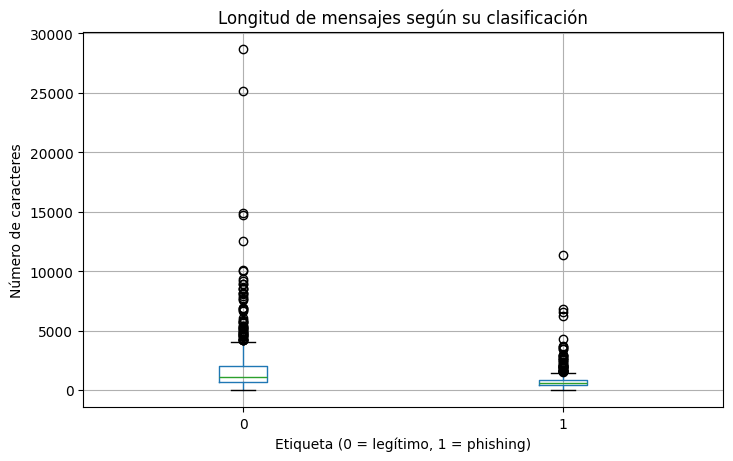

In [12]:

# Crear una copia de los textos para el análisis
spaphish_analysis = spaphish.copy()

spaphish_analysis["subject"] = spaphish_analysis["subject"].fillna("")
spaphish_analysis["body"] = spaphish_analysis["body"].fillna("")

spaphish_analysis["full_text"] = (
    spaphish_analysis["subject"] + " " +
    spaphish_analysis["body"]
).str.strip()

spaphish_analysis["text_length"] = (
    spaphish_analysis["full_text"].str.len()
)

print("Estadísticas de longitud:")
display(
    spaphish_analysis.groupby("Label")["text_length"]
    .describe()
    .round(1)
)

# Comparar la longitud de los mensajes por clase
spaphish_analysis.boxplot(
    column="text_length",
    by="Label",
    figsize=(8, 5)
)

plt.title("Longitud de mensajes según su clasificación")
plt.suptitle("")
plt.xlabel("Etiqueta (0 = legítimo, 1 = phishing)")
plt.ylabel("Número de caracteres")
plt.show()


In [13]:
# Crear el dataset normalizado de SpaPhish
spaphish_clean = spaphish[["subject", "body", "Label"]].copy()

# Completar los asuntos vacíos y construir el texto
spaphish_clean["subject"] = spaphish_clean["subject"].fillna("")
spaphish_clean["body"] = spaphish_clean["body"].fillna("")

spaphish_clean["text"] = (
    spaphish_clean["subject"].str.strip() + " " +
    spaphish_clean["body"].str.strip()
).str.strip()

# Normalizar el nombre de la etiqueta
spaphish_clean = spaphish_clean.rename(columns={"Label": "label"})

# Eliminar registros sin contenido
spaphish_clean = spaphish_clean[
    spaphish_clean["text"].str.len() > 0
].copy()

# Añadir la procedencia
spaphish_clean["source"] = "spaphish"

# Conservar únicamente las columnas necesarias
spaphish_clean = spaphish_clean[
    ["text", "label", "source"]
].reset_index(drop=True)

print("Dimensiones:", spaphish_clean.shape)
print("\nDistribución de etiquetas:")
display(spaphish_clean["label"].value_counts())


Dimensiones: (1395, 3)

Distribución de etiquetas:


,count
label,
1,731
0,664


In [16]:
print("Dimensions:", spaphish_clean.shape)

print("\nMissing values:")
display(spaphish_clean.isna().sum())

print("\nEmpty texts:", (spaphish_clean["text"].str.strip() == "").sum())

print("\nDuplicate texts:", spaphish_clean["text"].duplicated().sum())

print("\nLabel distribution:")
display(
    spaphish_clean["label"].value_counts().sort_index()
)

print("\nText examples:")
display(spaphish_clean[["text", "label"]].sample(3, random_state=42))

Dimensions: (1395, 3)

Missing values:


,0
text,0
label,0
source,0



Empty texts: 0

Duplicate texts: 0

Label distribution:


,count
label,
0,664
1,731



Text examples:


,text,label
1216,Resumen semanal de Luisa Fernanda Agudelo Fuen...,0
420,ÚLTIMA ALERTA: ¡TODAS TUS FOTOS SERÁN BORRADAS...,1
1383,⚠️Estás usando un 86% de tu almacenamiento de ...,0


In [14]:
for label in sorted(spamspa_train["label"].dropna().unique()):
    print(f"\n--- Etiqueta {label} ---")
    display(
        spamspa_train.loc[
            spamspa_train["label"] == label,
            "text"
        ].dropna().head(5)
    )



--- Etiqueta 0 ---


,text
0,No está pasando nada genial. Adiós
1,"No lo haré. Entonces, ¿qué pasa con los chicos?"
2,"Ok, k..sry, conozco 2 siva..tats y pregunté.."
3,Dónde estás ? A qué te dedicas ? ¿Cómo puedes ...
4,¿Aún no has terminado de trabajar o algo así?



--- Etiqueta 1 ---


,text
9,NOKIA o Motorola GRATIS con hasta 12 meses de ...
15,¡Llame al 09094100151 para usar sus minutos! L...
22,¿Quieres un nuevo videoteléfono? 750 en cualqu...
31,Tienes un anuncio importante de servicio al cl...
39,Tienes un anuncio importante de servicio al cl...


## Conclusiones del análisis y comprensión de los datos

Durante esta primera fase se han cargado y explorado los datasets seleccionados para el proyecto Avizor: SpaPhish y SpamSpa, además de identificar sus características principales y comprobar su calidad.

### SpaPhish

El dataset SpaPhish contiene 1.395 correos electrónicos en español y 47 columnas. Incluye información sobre el asunto y el cuerpo del mensaje, fechas, URLs, archivos adjuntos y anotaciones relacionadas con técnicas de ingeniería social.

La variable `Label` presenta dos categorías:
- `0`: correo legítimo (664 registros, 47,6 %).
- `1`: phishing (731 registros, 52,4 %).

La distribución está bastante equilibrada, lo que resulta favorable para desarrollar un primer clasificador binario.

En cuanto a la calidad de los datos:
- No se han encontrado filas duplicadas ni hashes repetidos.
- Hay 3 asuntos vacíos, pero todos los registros tienen cuerpo.
- Los valores ausentes en `attachments_types` y `attachments_sizes` corresponden a mensajes sin archivos adjuntos.
- Los valores ausentes en `urls` observados corresponden a registros con cero URLs.
- Se han detectado 24 fechas ausentes y algunos valores ausentes en columnas de justificación de las anotaciones.

El análisis de longitud muestra diferencias entre las clases: los mensajes legítimos tienen una longitud media de aproximadamente 1.802 caracteres, mientras que los mensajes de phishing tienen una media de unos 758 caracteres. Esta diferencia es descriptiva y no debe interpretarse como una regla suficiente para detectar phishing.

La comprobación de coherencia entre url_count y urls no ha detectado inconsistencias. Todos los registros con url_count = 0 tienen la columna urls vacía, mientras que los registros con url_count > 0 contienen información sobre las URLs. Por tanto, los valores ausentes de esta columna se consideran ausencias estructurales y no errores de los datos.

### SpamSpa

Los archivos de SpamSpa se distribuyen en dos conjuntos:
- Entrenamiento: 4.457 registros y 2 columnas (`text`, `label`).
- Test: 1.115 registros y 2 columnas.

La distribución de etiquetas es similar en ambos conjuntos:
- `0`: 3.859 registros en train y 966 en test.
- `1`: 598 registros en train y 149 en test.

La proporción aproximada es del 86,6 % para la clase 0 y del 13,4 % para la clase 1, por lo que existe un desequilibrio entre clases.

La inspección de ejemplos indica que:
- `0` representa mensajes normales (*ham*).
- `1` representa mensajes de spam.

Se han detectado 275 filas duplicadas en train y 25 en test. Además, 118 textos aparecen en ambos conjuntos, lo que representa aproximadamente el 10,83 % de los textos distintos del conjunto de test. Este solapamiento debe tenerse en cuenta, ya que puede producir una evaluación demasiado optimista si se utiliza directamente esta separación.

También se han encontrado dos textos vacíos en el conjunto de entrenamiento.

### Decisiones para el desarrollo del modelo

Los dos datasets no utilizan la misma definición de las clases positivas:

- SpaPhish distingue entre correos legítimos y phishing.
- SpamSpa distingue entre mensajes normales y spam.

Por tanto, no se combinarán directamente como si ambas etiquetas representaran el mismo fenómeno. El spam no equivale necesariamente a phishing.

Para el primer modelo de detección de phishing se utilizará SpaPhish, por ser un conjunto específicamente orientado a esa tarea y presentar una distribución equilibrada.

En la preparación del primer clasificador se utilizarán el asunto y el cuerpo del correo como contenido textual. No se incluirán las columnas de anotaciones, justificaciones o indicadores derivados de la clasificación, para evitar introducir información que pueda provocar fuga de datos (*data leakage*).

SpamSpa se conservará como una posible fuente para desarrollar posteriormente un clasificador complementario de spam.

### Limitaciones identificadas

- SpaPhish tiene un tamaño relativamente reducido para entrenar un modelo generalizable.
- SpamSpa presenta desequilibrio de clases, duplicados y solapamiento entre train y test.
- Las etiquetas de ambos datasets representan problemas diferentes.
- Los resultados obtenidos con estos datos no garantizan por sí solos un buen rendimiento en mensajes reales recibidos por personas mayores.

Será necesario evaluar el modelo con métricas como precision, recall y F1-score, prestando especial atención a los falsos negativos y falsos positivos.

